# 03 – La météo SIM2 de Météo-France

## Leçon 1 – Pourquoi changer de source météo ?

Dans le projet 13, l'API Open-Meteo nous avait bloqués (erreur 429 « trop de requêtes ») pour seulement 52 points. Pour 3 505 communes, c'était impossible.

**SIM2** (Safran-Isba-Modcou) est la ré-analyse météo et hydrologique de **Météo-France** :
- une **grille de 8 km × 8 km** qui couvre toute la France métropolitaine (9 892 points), Corse comprise ;
- des données **quotidiennes depuis 1958**, en **open data** (Licence Ouverte Etalab) ;
- distribuées sous forme de **fichiers annuels** (≈ 137 Mo compressés) → pas d'API, pas de quota : on télécharge le fichier et on prend ce dont on a besoin.

En bonus, SIM2 contient une variable très précieuse pour les feux : l'**indice d'humidité des sols** (SWI). Un sol sec = une végétation sèche.

## Leçon 2 – Les variables qu'on garde

| Colonne SIM2 | Signification | Unité | Notre nom |
|---|---|---|---|
| PRELIQ + PRENEI | pluie + neige | mm | `pluie` |
| T | température moyenne | °C | `temp_moy` |
| TSUP_H | température maximale | °C | `temp_max` |
| FF | vent moyen à 10 m | m/s → **km/h** (× 3,6) | `vent_moy` |
| HU | humidité relative moyenne | % | `humidite_moy` |
| ETP | évapotranspiration potentielle | mm | `evapo` |
| SWI | indice d'humidité des sols | 0 = sec, 1 = saturé | `humidite_sol` |

⚠️ SIM2 donne le vent **moyen** et l'humidité **moyenne** de la journée, pas le vent max ni l'humidité min comme Open-Meteo. Les rafales de mistral seront donc moins visibles. Toute source a ses compromis.

In [1]:
import os
import time
import requests
import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

DOSSIER_BRUT = "../data/raw/sim2"
DOSSIER_EXTRAIT = "../data/processed/sim2"
os.makedirs(DOSSIER_BRUT, exist_ok=True)
os.makedirs(DOSSIER_EXTRAIT, exist_ok=True)

URL = "https://meteofrance.s3.sbg.io.cloud.ovh.net/data/REF_CC/SIM"
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str})

`os.makedirs(..., exist_ok=True)` crée un dossier s'il n'existe pas, sans erreur s'il existe déjà. C'est l'équivalent Python de `mkdir -p`, et ça marche aussi depuis PowerShell.

## Étape 1 – La grille SAFRAN

Météo-France fournit les coordonnées des 9 892 points de la grille. Les colonnes `LAMBX` / `LAMBY` sont en **Lambert II étendu** (en hectomètres) : c'est l'identifiant du point dans les fichiers météo. Les colonnes `LAT_DG` / `LON_DG` donnent la latitude / longitude.

Le fichier utilise la **virgule décimale** (format français) → `decimal=","`.

In [2]:
fichier_grille = f"{DOSSIER_BRUT}/coordonnees_grille_safran_lambert-2-etendu.csv"
if not os.path.exists(fichier_grille):
    with open(fichier_grille, "wb") as f:
        f.write(requests.get(f"{URL}/coordonnees_grille_safran_lambert-2-etendu.csv", timeout=60).content)

grille = pd.read_csv(fichier_grille, sep=";", decimal=",")
grille.columns = ["LAMBX", "LAMBY", "lat", "lon"]
print(grille.shape)   # attendu : (9892, 4)
grille.head()

(9892, 4)


,LAMBX,LAMBY,lat,lon
0,600,24010,48.3822,-4.96118
1,760,24170,48.5386,-4.76561
2,760,24090,48.4670,-4.75585
3,760,24010,48.3953,-4.74612
4,760,23930,48.3237,-4.73641


## Leçon 3 – Trouver le point de grille le plus proche (plus proche voisin)

Pour chaque commune, on veut le point SAFRAN le plus proche de son centre. Approche naïve : calculer la distance de chaque commune à chaque point = 3 505 × 9 892 ≈ 35 millions de distances. Ça passe, mais il existe mieux.

Un **BallTree** (de scikit-learn) range les points dans une structure d'arbre, comme un index de base de données. Ça permet de trouver le plus proche voisin **sans tout comparer**. C'est la même mécanique que l'algorithme des *k plus proches voisins* (k-NN), un modèle classique de ML.

`metric="haversine"` = distance **sur la sphère terrestre**. Elle attend des angles en **radians** (`np.radians`) et renvoie une distance angulaire qu'on multiplie par le rayon de la Terre (6 371 km).

In [3]:
arbre = BallTree(np.radians(grille[["lat", "lon"]].values), metric="haversine")
distance, indice = arbre.query(np.radians(communes[["lat", "lon"]].values), k=1)

communes["LAMBX"] = grille["LAMBX"].values[indice[:, 0]]
communes["LAMBY"] = grille["LAMBY"].values[indice[:, 0]]
communes["dist_point_km"] = distance[:, 0] * 6371

print("points SAFRAN utilisés :", communes[["LAMBX", "LAMBY"]].drop_duplicates().shape[0])
communes["dist_point_km"].describe().round(2)

points SAFRAN utilisés : 1215


count    3505.00
mean        3.07
std         1.15
min         0.03
25%         2.31
50%         3.21
75%         3.92
max         5.64
Name: dist_point_km, dtype: float64

**Attendu :** **1 215 points** pour 3 505 communes, distance moyenne ≈ 3,1 km, max ≈ 5,6 km. C'est logique pour une grille de 8 km : on est toujours à moins d'une demi-diagonale (≈ 5,7 km) d'un point.

Plusieurs petites communes voisines partagent le même point météo, comme les « cases » de 0,1° du projet 13, mais ici la grille est **officielle** et plus fine.

In [4]:
points = communes[["LAMBX", "LAMBY"]].drop_duplicates()
communes.to_csv("../data/processed/communes_med.csv", index=False)

## Leçon 4 – Récupérer « petit à petit » : la boucle télécharger → extraire → libérer

Chaque fichier annuel décompressé fait ≈ 3,6 millions de lignes × 29 colonnes, pour **toute la France**. On n'en veut qu'une fraction (nos 1 215 points × 7 variables).

Stratégie, année par année :
1. **Si l'extraction existe déjà** (`meteo_2016.parquet`) → on passe (c'est notre « cache », comme `requests_cache` dans le projet 13) ;
2. sinon, on **télécharge** le fichier annuel (s'il n'est pas déjà là) ;
3. on le **lit en ne gardant que les colonnes utiles** (`usecols`) ;
4. on **filtre** nos points avec un `merge` (jointure interne) ;
5. on **sauvegarde** l'extrait en Parquet ;
6. on **supprime** le gros fichier brut (le disque n'est pas infini !).

**Quelles années ?** On prend **1995 → 2025** (31 fichiers) :
- **2016-2025** : les années où l'on connaît aussi les feux → elles servent à **entraîner et évaluer** le modèle ;
- **1996-2015** : pas de feux BDIFF pour ces années, mais leur **météo** servira aux **scénarios 2027** (notebook 08). Le modèle a besoin des feux pour *apprendre*, mais pour *rejouer* une météo possible, il n'a besoin que… de météo. On aura ainsi **30 étés** différents au lieu de 10 ;
- **1995** : un « préchauffage ». Le 1ᵉʳ janvier 1996, il faudra connaître la pluie des 30 jours précédents.

Le téléchargement se fait en **flux** (`stream=True`) par morceaux de 1 Mo : le fichier est écrit au fur et à mesure, sans tout charger en mémoire.

In [5]:
COLONNES = ["LAMBX", "LAMBY", "DATE", "PRELIQ", "PRENEI", "T", "TSUP_H", "FF", "HU", "ETP", "SWI"]
GARDER_BRUTS = False   # True pour conserver les fichiers annuels (≈ 1,5 Go)


def telecharger(annee):
    chemin = f"{DOSSIER_BRUT}/QUOT_SIM2_{annee}.csv.gz"
    if os.path.exists(chemin):
        return chemin
    for essai in range(5):
        try:
            with requests.get(f"{URL}/QUOT_SIM2_{annee}.csv.gz", stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(chemin + ".part", "wb") as f:
                    for morceau in r.iter_content(chunk_size=1_000_000):
                        f.write(morceau)
            os.rename(chemin + ".part", chemin)   # le fichier n'apparaît qu'une fois complet
            return chemin
        except requests.RequestException as e:
            print(f"  erreur ({e}), nouvel essai dans 30 s")
            time.sleep(30)
    raise RuntimeError(f"échec du téléchargement {annee}")


for annee in range(1995, 2026):
    sortie = f"{DOSSIER_EXTRAIT}/meteo_{annee}.parquet"
    if os.path.exists(sortie):
        print(annee, "déjà extrait")
        continue
    debut = time.time()
    brut = pd.read_csv(telecharger(annee), sep=";", usecols=COLONNES)
    extrait = brut.merge(points, on=["LAMBX", "LAMBY"], how="inner")
    extrait.to_parquet(sortie, index=False)
    if not GARDER_BRUTS:
        os.remove(f"{DOSSIER_BRUT}/QUOT_SIM2_{annee}.csv.gz")
    print(f"{annee} : {len(brut):>9} lignes France → {len(extrait):>7} gardées  ({time.time() - debut:.0f} s)")

1995 déjà extrait
1996 déjà extrait
1997 déjà extrait
1998 déjà extrait
1999 déjà extrait
2000 déjà extrait
2001 déjà extrait
2002 déjà extrait
2003 déjà extrait
2004 déjà extrait
2005 déjà extrait
2006 déjà extrait
2007 déjà extrait
2008 déjà extrait
2009 déjà extrait
2010 déjà extrait
2011 déjà extrait
2012 déjà extrait
2013 déjà extrait
2014 déjà extrait
2015 déjà extrait
2016 déjà extrait
2017 déjà extrait
2018 déjà extrait
2019 déjà extrait
2020 déjà extrait
2021 déjà extrait
2022 déjà extrait
2023 déjà extrait
2024 déjà extrait
2025 déjà extrait


**Attendu :** pour chaque année, ≈ 3,6 millions de lignes France → ≈ 444 000 lignes gardées (1 215 points × 365 jours), en ≈ 5 s de lecture par année, plus le téléchargement de ≈ 137 Mo (quelques secondes à une minute selon ta connexion). Compte ≈ 5 à 30 minutes pour les 31 années.

Si la boucle s'interrompt (coupure réseau…), il suffit de la **relancer** : les années déjà extraites sont sautées, et un téléchargement interrompu (fichier `.part`) est recommencé.

## Étape 2 – Assembler les 31 années et mettre en forme

In [6]:
meteo = pd.concat(
    [pd.read_parquet(f"{DOSSIER_EXTRAIT}/meteo_{a}.parquet") for a in range(1995, 2026)],
    ignore_index=True,
)
meteo["jour"] = pd.to_datetime(meteo["DATE"].astype(str), format="%Y%m%d")

meteo = pd.DataFrame({
    "LAMBX": meteo["LAMBX"], "LAMBY": meteo["LAMBY"], "jour": meteo["jour"],
    "pluie": meteo["PRELIQ"] + meteo["PRENEI"],
    "temp_moy": meteo["T"],
    "temp_max": meteo["TSUP_H"],
    "vent_moy": meteo["FF"] * 3.6,        # m/s → km/h
    "humidite_moy": meteo["HU"],
    "evapo": meteo["ETP"],
    "humidite_sol": meteo["SWI"],
})
print(meteo.shape)            # attendu : (13757445, 10) = 1 215 points × 11 323 jours
print(meteo.isna().sum().sum())   # attendu : 0
meteo.describe().round(1).T

(13757445, 10)


0


,count,mean,min,25%,50%,75%,max,std
LAMBX,13757445.0,8257.4,5480.0,7000.0,8120.0,9160.0,11960.0,1610.2
LAMBY,13757445.0,18654.8,16250.0,18090.0,18730.0,19370.0,20410.0,894.1
jour,13757445,2010-07-02 00:00:00,1995-01-01 00:00:00,2002-10-01 00:00:00,2010-07-02 00:00:00,2018-04-02 00:00:00,2025-12-31 00:00:00,NaN
pluie,13757445.0,2.6,0.0,0.0,0.0,1.0,493.5,8.4
temp_moy,13757445.0,11.9,-20.6,6.4,11.6,17.6,34.4,7.5
temp_max,13757445.0,16.4,-19.5,10.3,16.1,22.8,43.1,8.4
vent_moy,13757445.0,9.6,0.0,5.0,7.6,12.2,85.0,6.7
humidite_moy,13757445.0,70.5,9.5,60.9,71.2,80.8,99.9,13.6
evapo,13757445.0,2.6,0.1,1.0,2.2,3.9,12.3,1.8
humidite_sol,13757445.0,0.6,-0.1,0.3,0.6,0.8,2.1,0.3


`format="%Y%m%d"` explique à pandas comment lire `20160101` : année sur 4 chiffres, mois sur 2, jour sur 2.

**Contrôles de vraisemblance** (toujours regarder min / moyenne / max) :
- `temp_max` va de −18 °C (sommets alpins en hiver) à **43,1 °C** (le 28 juin 2019, record de canicule dans le Gard) ✔️
- `vent_moy` moyen ≈ 10 km/h, max ≈ 82 km/h (moyenne sur la journée, d'où des valeurs plus faibles qu'un vent max) ✔️
- `humidite_sol` : surtout entre 0 et 1, avec quelques valeurs > 1 (sols saturés après de fortes pluies) ✔️

## Étape 3 – Un coup d'œil : l'humidité des sols raconte les étés secs

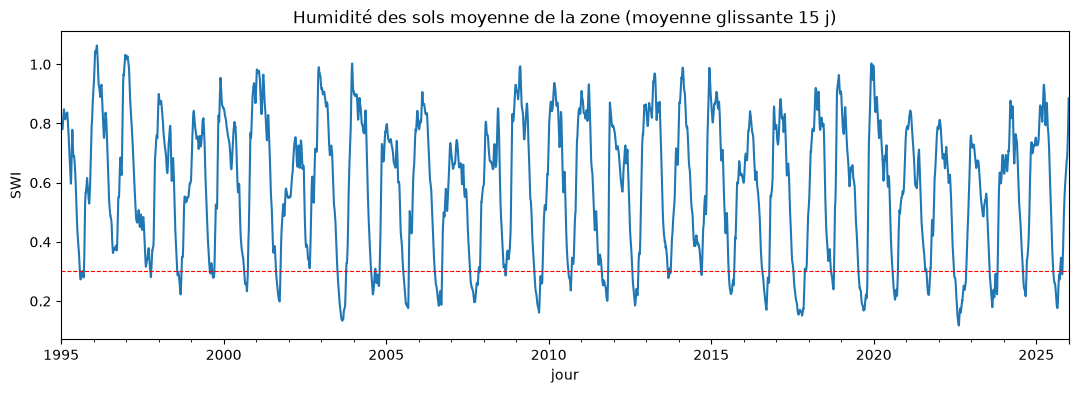

In [7]:
import matplotlib.pyplot as plt

moyenne = meteo.groupby("jour")[["humidite_sol"]].mean()
moyenne["humidite_sol"].rolling(15).mean().plot(figsize=(13, 4), title="Humidité des sols moyenne de la zone (moyenne glissante 15 j)")
plt.axhline(0.3, color="red", linestyle="--", linewidth=0.8)
plt.ylabel("SWI")
plt.show()

**Lecture :** chaque été, l'humidité des sols plonge. L'été **2022** est de loin le plus sec (SWI moyen juin-sept. 0,21), devant **2017** (0,25), **2019** (0,27) et **2025** (0,30) ; l'été **2018** est le plus humide (0,44). Rappel de l'exploration : 2017 est l'année record en feux et 2018 la plus calme → le lien saute aux yeux.

## Étape 4 – Sauvegarde

On garde la météo **au niveau des points** (13,8 millions de lignes) et pas des communes (3 fois plus). On calculera les variables glissantes **par point** dans le notebook 04, ce qui fait 3 fois moins de calculs, puis on les copiera vers les communes avec la table de correspondance.

In [8]:
meteo.to_parquet("../data/processed/meteo_points_med.parquet", index=False)
print(f"{os.path.getsize('../data/processed/meteo_points_med.parquet') / 1e6:.0f} Mo")

109 Mo


## 🎯 À toi de jouer

1. Quelle commune est la **plus éloignée** de son point SAFRAN ? (`communes.sort_values("dist_point_km")`)
2. Quel jour a eu la **température maximale la plus élevée** sur la zone, et à quel point ?

In [9]:
# à toi

<details><summary>Correction</summary>

```python
communes.sort_values("dist_point_km", ascending=False).head(3)[["nom", "dept", "dist_point_km"]]

meteo.loc[meteo["temp_max"].idxmax()]
```
`idxmax()` renvoie l'**index** de la ligne qui contient le maximum ; `.loc[...]` va chercher cette ligne.
</details>

## Récap

1. **SIM2** : ré-analyse Météo-France, grille 8 km, fichiers annuels open data, sans quota. On en prend **31 ans** (1995-2025).
2. **Plus proche voisin** (BallTree, distance haversine) : 3 505 communes → 1 215 points météo.
3. Boucle **télécharger → extraire → sauvegarder → supprimer**, relançable grâce au cache Parquet.
4. Une variable nouvelle et précieuse : l'**humidité des sols**.

**Prochaine étape (04) :** agréger tout ça et créer les features.